# 02. Entrenamiento y Evaluación de Modelos
Este notebook procesa la matriz limpia y etiquetada (proveniente de la fase ETL) para realizar la división cronológica estricta (Hold-out 60/40), aplicar el escalado de características y evaluar el rendimiento predictivo de tres algoritmos: Regresión Logística, Máquinas de Vectores de Soporte (SVM) y Random Forest. El desbalanceo natural de clases se corrige mediante el parámetro de pesos ponderados (`class_weight='balanced'`). Finalmente, se construye una tabla comparativa de resultados y se exportan las visualizaciones definitivas para el informe técnico.

In [1]:
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

# 1. Definir ruta local relativa
ruta_dataset = "../data/processed/Dataset_Master_Etiquetado.csv"

# Verificar existencia del archivo
if not os.path.exists(ruta_dataset):
    raise FileNotFoundError(f"No se encontro el archivo: {ruta_dataset}. Se requiere ejecutar la fase ETL previa.")

# 2. Cargar el dataset etiquetado
df = pd.read_csv(ruta_dataset)
print("Dataset etiquetado cargado correctamente. Registros totales:", len(df))

Dataset etiquetado cargado correctamente. Registros totales: 112


In [2]:
#PREPARACION DE DATOS (Hold-out Cronologico y Escalado)
from sklearn.preprocessing import StandardScaler

# Separar Variables Predictoras (X) y Variable Objetivo (y)
columnas_excluir = ['SEMANA_EPIDEMIOLOGICA', 'CASOS_PROXIMA_SEMANA_t_1', 'NIVEL_INCIDENCIA', 'CASOS_DENGUE']
X = df.drop(columns=columnas_excluir)
y = df['NIVEL_INCIDENCIA']

# Split Cronologico (60% Train, 40% Test)
corte = int(len(df) * 0.60)
X_train, X_test = X.iloc[:corte], X.iloc[corte:]
y_train, y_test = y.iloc[:corte], y.iloc[corte:]

print("Division temporal del dataset finalizada:")
print(f" - Conjunto de Entrenamiento (Train): {len(X_train)} semanas.")
print(f" - Conjunto de Prueba (Test): {len(X_test)} semanas.\n")

# Escalado de datos mediante StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Conservar copia original para Random Forest (invariante a escala)
X_train_rf, X_test_rf = X_train.copy(), X_test.copy()
print("Transformacion y escalado de caracteristicas completado.")

Division temporal del dataset finalizada:
 - Conjunto de Entrenamiento (Train): 67 semanas.
 - Conjunto de Prueba (Test): 45 semanas.

Transformacion y escalado de caracteristicas completado.


In [3]:
#EVALUACION DE MODELOS Y MATRIZ COMPARATIVA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score
from IPython.display import display

print("Iniciando entrenamiento y evaluacion de modelos...\n")

# A. Regresion Logistica (Baseline Lineal paramétrico)
lr_model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

# B. Support Vector Machine (Kernel RBF para fronteras no lineales)
svm_model = SVC(kernel='rbf', random_state=42, class_weight='balanced')
svm_model.fit(X_train_scaled, y_train)
svm_pred = svm_model.predict(X_test_scaled)

# C. Random Forest Classifier (Ensamble basado en arboles)
rf_model = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, class_weight='balanced')
rf_model.fit(X_train_rf, y_train)
rf_pred = rf_model.predict(X_test_rf)

# Impresion de reporte
print("MODELO 1: REGRESIÓN LOGÍSTICA (Baseline Lineal)")
print(classification_report(y_test, lr_pred))

print("MODELO 2: SVM (Kernel RBF - Fronteras no lineales)")
print(classification_report(y_test, svm_pred))

print("MODELO 3: RANDOM FOREST (Ensamble Lógico)")
print(classification_report(y_test, rf_pred))

# Extraccion de metricas para la Tabla Comparativa
def extraer_metricas_completas(y_true, y_pred, nombre_modelo):
    acc = accuracy_score(y_true, y_pred)
    report = classification_report(y_true, y_pred, output_dict=True)
    
    # Función auxiliar para extraer de forma segura
    def get_val(clase, metrica):
        return f"{report[clase][metrica]:.2f}" if clase in report else "0.00"
        
    return {
        'Modelo': nombre_modelo, 
        'Accuracy': f"{acc*100:.2f}%", 
        'Recall (Alto)': get_val('Alto', 'recall'),
        'Recall (Medio)': get_val('Medio', 'recall'),
        'Recall (Bajo)': get_val('Bajo', 'recall'),
        'F1-Score (Alto)': get_val('Alto', 'f1-score'),
        'F1-Score (Medio)': get_val('Medio', 'f1-score'),
        'F1-Score (Bajo)': get_val('Bajo', 'f1-score')
    }

resultados_evaluacion = [
    extraer_metricas_completas(y_test, lr_pred, 'Regresion Logistica'),
    extraer_metricas_completas(y_test, svm_pred, 'SVM (Kernel RBF)'),
    extraer_metricas_completas(y_test, rf_pred, 'Random Forest')
]

df_comparativa = pd.DataFrame(resultados_evaluacion)

print("\n--- TABLA COMPARATIVA CONSOLIDADA (Visualización para informe) ---")
display(df_comparativa)

Iniciando entrenamiento y evaluacion de modelos...

MODELO 1: REGRESIÓN LOGÍSTICA (Baseline Lineal)
              precision    recall  f1-score   support

        Alto       0.56      0.31      0.40        16
        Bajo       0.38      0.73      0.50        11
       Medio       0.60      0.50      0.55        18

    accuracy                           0.49        45
   macro avg       0.51      0.51      0.48        45
weighted avg       0.53      0.49      0.48        45

MODELO 2: SVM (Kernel RBF - Fronteras no lineales)
              precision    recall  f1-score   support

        Alto       0.45      0.31      0.37        16
        Bajo       0.50      0.82      0.62        11
       Medio       0.31      0.28      0.29        18

    accuracy                           0.42        45
   macro avg       0.42      0.47      0.43        45
weighted avg       0.41      0.42      0.40        45

MODELO 3: RANDOM FOREST (Ensamble Lógico)
              precision    recall  f1-score  

,Modelo,Accuracy,Recall (Alto),Recall (Medio),Recall (Bajo),F1-Score (Alto),F1-Score (Medio),F1-Score (Bajo)
0,Regresion Logistica,48.89%,0.31,0.50,0.73,0.40,0.55,0.50
1,SVM (Kernel RBF),42.22%,0.31,0.28,0.82,0.37,0.29,0.62
2,Random Forest,64.44%,0.88,0.28,0.91,0.74,0.42,0.71


<Figure size 600x500 with 0 Axes>

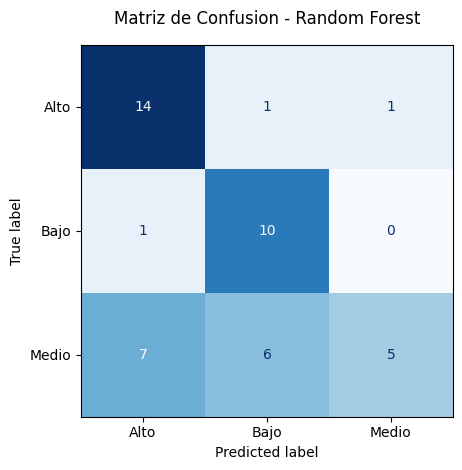

Figura 1 generada: ../models/figura1_matriz_confusion.png


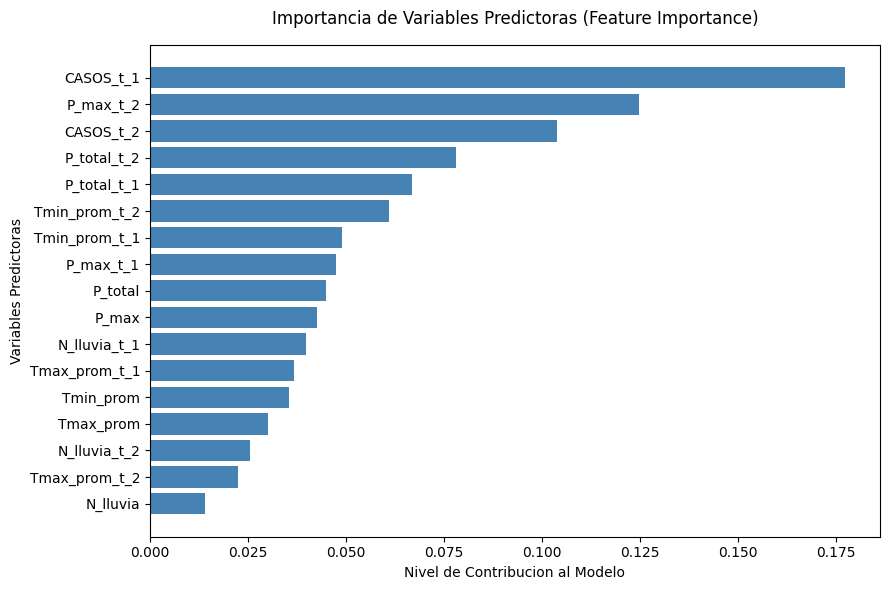

Figura 2 generada: ../models/figura2_feature_importance.png


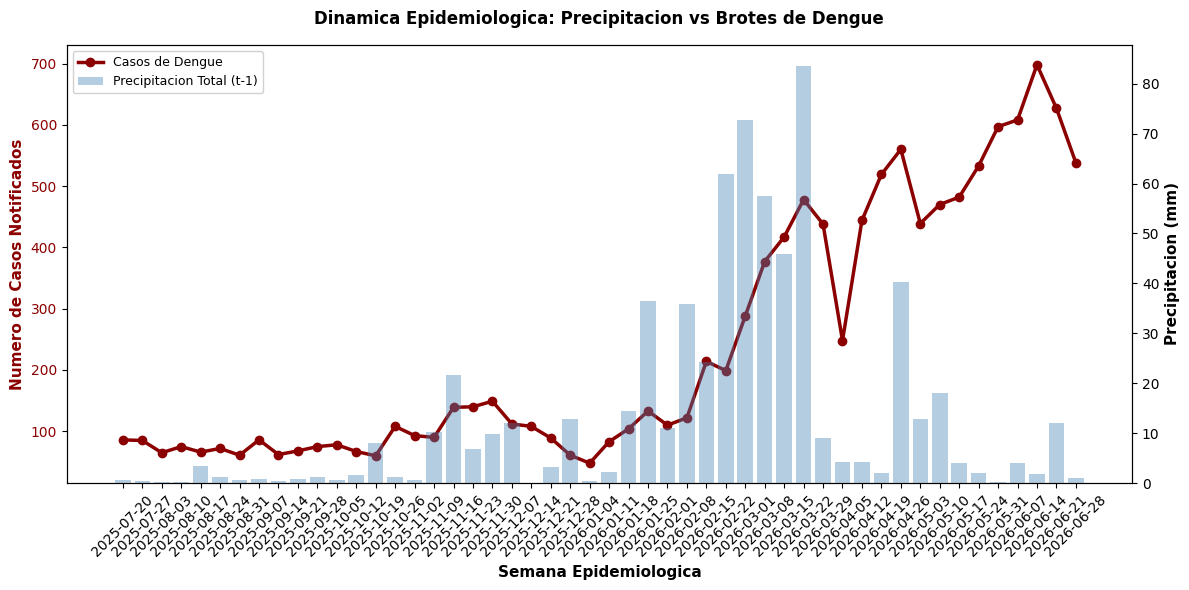

Figura 3 generada: ../models/figura3_dinamica_precipitacion.png


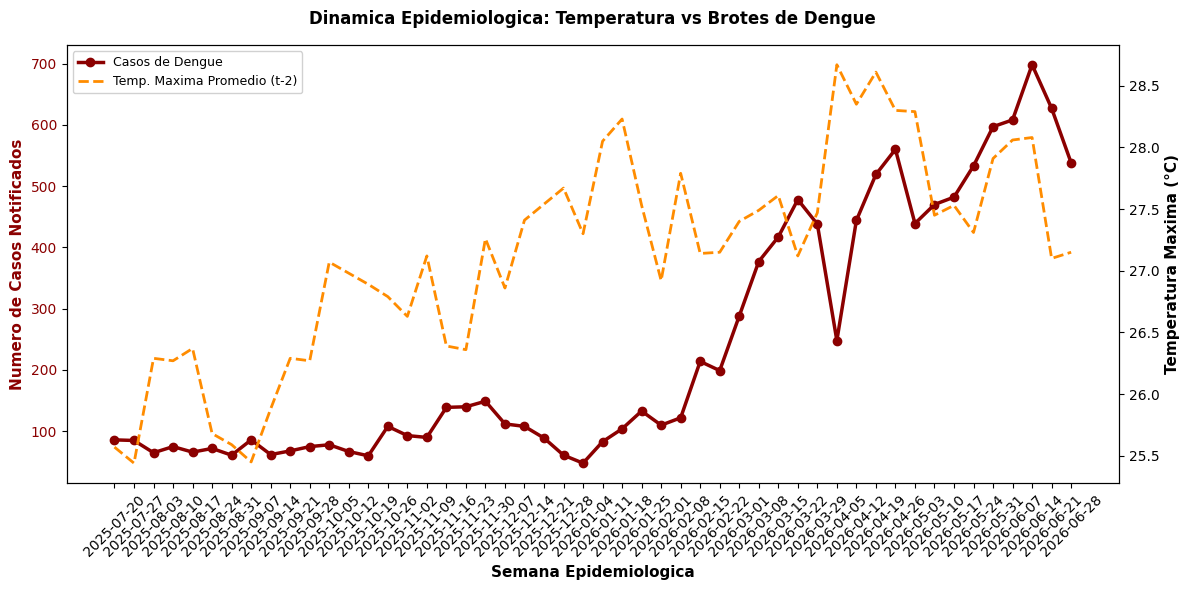

Figura 4 generada: ../models/figura4_dinamica_temperatura.png


In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

os.makedirs("../models", exist_ok=True)

#FIGURA 1: MATRIZ DE CONFUSION (RANDOM FOREST)
plt.figure(figsize=(6, 5))
disp = ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, cmap=plt.cm.Blues, colorbar=False)
plt.title('Matriz de Confusion - Random Forest', pad=15)
plt.tight_layout()
ruta_fig1 = "../models/figura1_matriz_confusion.png"
plt.savefig(ruta_fig1, dpi=300, bbox_inches='tight')
plt.show()
print(f"Figura 1 generada: {ruta_fig1}")

#FIGURA 2: IMPORTANCIA DE VARIABLES (FEATURE IMPORTANCE)
importancias = rf_model.feature_importances_
columnas = X_train_rf.columns
df_importancias = pd.DataFrame({'Variable': columnas, 'Importancia': importancias})
df_importancias = df_importancias.sort_values(by='Importancia', ascending=True)
        
plt.figure(figsize=(9, 6))
plt.barh(df_importancias['Variable'], df_importancias['Importancia'], color='steelblue')
plt.title('Importancia de Variables Predictoras (Feature Importance)', pad=15)
plt.xlabel('Nivel de Contribucion al Modelo')
plt.ylabel('Variables Predictoras')
plt.tight_layout()
ruta_fig2 ="../models/figura2_feature_importance.png"
plt.savefig(ruta_fig2, dpi=300, bbox_inches='tight')
plt.show()
print(f"Figura 2 generada: {ruta_fig2}")

# Segmento temporal comun para dinamica epidemiologica
df_plot = df.tail(50).copy()
# FIGURA 3: DINAMICA EPIDEMIOLOGICA (CASOS VS PRECIPITACION)

fig3, ax1 = plt.subplots(figsize=(12, 6))

l1 = ax1.plot(df_plot['SEMANA_EPIDEMIOLOGICA'], df_plot['CASOS_DENGUE'], 
              color='darkred', linewidth=2.5, marker='o',
              label='Casos de Dengue', zorder=3)
ax1.set_xlabel('Semana Epidemiologica', fontsize=11, fontweight='bold')
ax1.set_ylabel('Numero de Casos Notificados', color='darkred', fontsize=11, fontweight='bold')
ax1.tick_params(axis='y', labelcolor='darkred')
ax1.tick_params(axis='x', rotation=45)
   
ax2 = ax1.twinx()
l2 = ax2.bar(df_plot['SEMANA_EPIDEMIOLOGICA'], df_plot['P_total_t_1'],
             color='steelblue', alpha=0.4,
             label='Precipitacion Total (t-1)', zorder=1)
ax2.set_ylabel('Precipitacion (mm)', color='black', fontsize=11, fontweight='bold')
   
plt.title('Dinamica Epidemiologica: Precipitacion vs Brotes de Dengue', pad=15, fontweight='bold')
        
lineas3 = l1 + [l2]
etiquetas3 = [l.get_label() for l in lineas3]
ax1.legend(lineas3, etiquetas3, loc='upper left', fontsize=9, framealpha=0.9)

fig3.tight_layout()
ruta_fig3 = "../models/figura3_dinamica_precipitacion.png"
fig3.savefig(ruta_fig3, dpi=300, bbox_inches='tight')
plt.show()
print(f"Figura 3 generada: {ruta_fig3}")
#FIGURA 4: DINAMICA EPIDEMIOLOGICA (CASOS VS TEMPERATURA)

fig4, ax3 = plt.subplots(figsize=(12, 6))

l3 = ax3.plot(df_plot['SEMANA_EPIDEMIOLOGICA'], df_plot['CASOS_DENGUE'],
              color='darkred', linewidth=2.5, marker='o',
              label='Casos de Dengue', zorder=3)

ax3.set_xlabel('Semana Epidemiologica', fontsize=11, fontweight='bold')
ax3.set_ylabel('Numero de Casos Notificados', color='darkred',
               fontsize=11, fontweight='bold')
ax3.tick_params(axis='y', labelcolor='darkred')
ax3.tick_params(axis='x', rotation=45)

ax4 = ax3.twinx()

l4 = ax4.plot(df_plot['SEMANA_EPIDEMIOLOGICA'], df_plot['Tmax_prom_t_2'],
              color='darkorange', linewidth=2, linestyle='--',
              label='Temp. Maxima Promedio (t-2)', zorder=4)

ax4.set_ylabel('Temperatura Maxima (°C)', color='black',
               fontsize=11, fontweight='bold')

plt.title('Dinamica Epidemiologica: Temperatura vs Brotes de Dengue',
          pad=15, fontweight='bold')

lineas4 = l3 + l4
etiquetas4 = [l.get_label() for l in lineas4]

ax3.legend(lineas4, etiquetas4, loc='upper left',
           fontsize=9, framealpha=0.9)

fig4.tight_layout()

ruta_fig4 = "../models/figura4_dinamica_temperatura.png"
fig4.savefig(ruta_fig4, dpi=300, bbox_inches='tight')

plt.show()

print(f"Figura 4 generada: {ruta_fig4}")